In [1]:
import os
os.environ['PATH'] += os.pathsep + '/home/jupyter-ramith/.conda/envs/solab_jax/bin/'

In [2]:
import os
os.environ["CUDA_VISIBLE_DEVICES"] = "2"

In [3]:
import sys
sys.path.append("../")

import math
import jax
from jax import vmap
from jax import random
from jax import jit
import jax.numpy as jnp
from functools import partial

from typing import Dict, List
from jaxtyping import Array, Float

from modules.gt_tree_gen import *
from modules.perfect_binary_tree_helpers import *
from modules.vis_utils import *
from arg_parser_v2 import *

In [4]:
def update_probability(
        depth_bounds : List[int],
        ignored_nodes : Array,
        curr_prob_vector : Array
    ) -> Array:
    """Updates the probability array based on two things. 1) The depth bounds and 2) The mask

    Args:
        depth_bounds: list of depth bounds (upper and lower)
        ignored_nodes : list of nodes already removed or ignored (probabilities will be made zero)
        curr_prob_vector: current probabilities of the nodes in the tree

    Returns:
        updated probability vector
    """
    depth_u_bound = depth_bounds[1] # max depth of the perfect binary tree

    u_bound = get_max_node_id_for_depth(depth_bounds[0], depth_u_bound)
    l_bound = get_max_node_id_for_depth(depth_bounds[0]+1, depth_u_bound)

    curr_prob_vector = curr_prob_vector.at[0:u_bound].set(1)

    if(ignored_nodes.shape[0] > 0): # There are some nodes that we need to remove from selecting
        curr_prob_vector = curr_prob_vector.at[ignored_nodes].set(0)

    return curr_prob_vector

#### Prototyping the vscode, code

In [8]:
def extract_key_parts(adj):
    temp_adj = adj.at[-1,-1].set(0) # temporary copy
    
    blank_adj = jax.numpy.full_like(adj, 0)
    
    leaf_ids = find_children_ids(temp_adj, temp_adj.shape[0] - 1)
    leaf_ids = jnp.array([x.item() for x in leaf_ids]).sort()
    
    ance_ids = jnp.where(temp_adj.sum(axis = 0) == 2)[0].sort()
    orphans_ = jnp.where(adj.sum(axis = 1) == 0)[0]
    
    return leaf_ids, ance_ids, orphans_


    
#     leaf_ids = find_children_ids(temp_adj, temp_adj.shape[0] - 1)
#     leaf_ids = jnp.array([x.item() for x in leaf_ids]).sort()
#     ance_ids = jnp.where(temp_adj.sum(axis = 0) == 2)[0].sort()
#     orphans_ = jnp.where(adj.sum(axis = 1) == 0)[0]

In [23]:
def generate_general_groundtruth(
    metadata_ : Dict[str, int], 
    perfect : bool = False, 
    seed : int = 42, 
    verbose : bool = False,
    show_derivation : bool = False
    ):
    """Generates a random groundtruth example based on provided specs

    Args : 
        metadata:
            * number of leaves (N)
            * number of mutations (m)
            * number of letters (c)
            * sequence length (l)

        perfect : if True, the tree is perfect (all leaves have the same depth)
        seed : random seed
        verbose: print the number of leaves generated

    Returns:
        masked_main : masked sequences (shape = (n_all, seq_length)) -> leaves visible, ancestors masked
        true_main   : true sequences   (shape = (n_all, seq_length)) -> leaves & ancestors visible
        tree        : tree structure   (shape = (n_all, n_all)) 	 -> ground truth tree
    """
    metadata = metadata_.copy()
    n = metadata['n_leaves']

    if(perfect): 
        # perfect mode, possible only if N is a power of 2
        print_critical_info("Perfect tree mode")
        assert metadata['n_leaves'] == 2**int(math.log2(n))
        
        return generate_groundtruth(metadata, seed, verbose)
    else:
        
        # Compute params for the prospective perfect tree (upper bound for depth, how many to remove)
        depth_u_bound = math.ceil(math.log2(n))
        leaf_u_bound  = 2**int(depth_u_bound)
        leaves_to_remove     = leaf_u_bound - n
        metadata['n_leaves'] = leaf_u_bound
        
        # Generate the perfect tree
        print_bold_info(f"Generating perfect tree of {leaf_u_bound} leaves in order to make tree with {n} leaves, seed = {seed}")
        leaf_seqs, all_seqs, adj = generate_groundtruth(metadata, seed, verbose)

        # Initialize depth bounds
        # Based on how many to remove, which depth can we go as the most top level ?
        depth_bounds = [None, depth_u_bound]
        depth_bounds[0] = math.ceil(depth_u_bound - math.log2(leaves_to_remove+1)) 

        # Initialize params
        done = False if leaves_to_remove > 0 else True
        prob = jnp.zeros(leaf_u_bound + leaf_u_bound - 1)  # Probability Array (2*n-1 total nodes)
        nodes = jnp.array(range(leaf_u_bound + leaf_u_bound - 1))
        
        # Ignore all leaves (no point of removing them, we can remove parents)
        ignored_nodes = jnp.arange(leaf_u_bound)

        key = jax.random.PRNGKey(seed)
        
        k = 0
        while(not done):
            # Obtain valid updated probabilities
            prob = jnp.zeros(leaf_u_bound + leaf_u_bound - 1)
            prob = update_probability(depth_bounds, ignored_nodes, prob) 
            
            # Select an ancestor, to chop its both branches
            sel = random.choice(key, nodes, p=prob, axis=0)
            ## remove connections of these nodes from the tree
            adj, removed_leaf_count, nodes_in_path = remove_branches(adj, sel)
            
            # Keep track of all removed nodes (past, selected parent, nodes affected)
            ignored_nodes = jnp.concatenate([ignored_nodes, jnp.array([sel]), jnp.array(nodes_in_path)])
            
            # Update next bounds to pick 
            leaves_to_remove = leaves_to_remove - (removed_leaf_count - 1)
            depth_bounds[0] = math.ceil(depth_u_bound - math.log2(leaves_to_remove+1)) 
          
            if(leaves_to_remove == 0):
                done = True
                
            k+=1
            key, _ = random.split(key)
    
    ## Extract indices of key stuff
    leaf_ids, ance_ids, orphans_ = extract_key_parts(adj)
    
    ## Extract leaves and ancestors from the original seq matrix
    extracted_leaves = all_seqs[leaf_ids]
    extracted_ancestors = all_seqs[ance_ids]
    
    ## Checking whether groundtruth generation worked correctly
    assert n == extracted_leaves.shape[0]
    
    dummy_ancestors = jnp.zeros((n-1, extracted_leaves.shape[1]))
    new_leaves = jnp.vstack((extracted_leaves, dummy_ancestors))
    
    ## Cleanup the pruned tree by removing orphan nodes
    shrinked_adj = adj.copy()
    shrinked_adj = jnp.delete(shrinked_adj, orphans_, axis = 0)
    shrinked_adj = jnp.delete(shrinked_adj, orphans_, axis = 1)
    
    ## Extract indices of key stuff
    new_leaf_ids, new_ance_ids, new_orphans_ = extract_key_parts(shrinked_adj)
    
    ## Build a new seqs matrix with correct ordering which matches shrinked_adj
    new_all_seqs = jnp.zeros((new_leaves.shape[0], new_leaves.shape[1]))
    new_all_seqs = new_all_seqs.at[new_leaf_ids].set(extracted_leaves)
    new_all_seqs = new_all_seqs.at[new_ance_ids].set(extracted_ancestors)
    
 
    if(show_derivation):
        '''
            For debugging purposes (displaying how perfect tree was pruned)
        '''
        
        print(all_seqs)
        print_critical_info(f"-> extracting new leaf ids : {leaf_ids}")
        print_critical_info(f"-> extracting remaining ancestor ids : {ance_ids}")
        
        print_success_info(f"Extracted Leaves")
        print_success_info(f"\n{extracted_leaves}")
        
        print_success_info(f"Constructed New Seq Matrix")
        print_success_info(f"\n{new_all_seqs}")
        
        orphans = jnp.where(adj.sum(axis = 1) == 0)[0]

        label_names = {}
        for i in range(0, adj.shape[0]):
            if i in orphans:
                continue
            label_names[i] = str(i)
        
        # plot original numbering, displaying what's left
        fig = show_graph_with_labels(adj, n, [label_names, leaf_ids], True)
        
    
        label_names  = {}
        for i in range(0, shrinked_adj.shape[0]):
            label_names[i] = str(i) 
        
        return [new_leaves, new_leaf_ids, new_ance_ids], [new_all_seqs, label_names], [shrinked_adj,  adj, fig]

    ##            
    return new_leaves, new_all_seqs, shrinked_adj

In [42]:
l = 19
seed = 235

metadata = {
    'n_all' : 2*l-1,
    'n_leaves' : l, 
    'n_ancestors' : l-1,
    'seq_length' : 4,
    'n_letters' : 4,
    'n_mutations' : 2,
}

[new_leaves, leaf_ids, new_ance_ids], [new_all_seqs, label_names], [shrinked_adj,  adj, fig] = generate_general_groundtruth(metadata, perfect=False, seed = seed, show_derivation = True)

Generating perfect tree of 32 leaves in order to make tree with 19 leaves, seed = 235 

Explicitly requested dtype <class 'jax.numpy.int64'> requested in zeros is not available, and will be truncated to dtype int32. To enable more dtypes, set the jax_enable_x64 configuration option or the JAX_ENABLE_X64 shell environment variable. See https://github.com/google/jax#current-gotchas for more.


[[2 2 2 2]
 [3 0 2 2]
 [3 2 0 2]
 [1 2 2 2]
 [0 1 2 3]
 [0 3 0 2]
 [2 3 1 3]
 [1 3 1 0]
 [3 0 0 0]
 [3 2 2 2]
 [3 3 3 0]
 [2 3 3 0]
 [1 0 3 3]
 [0 1 0 0]
 [1 1 0 0]
 [0 2 2 0]
 [3 2 2 2]
 [3 3 2 1]
 [2 0 0 3]
 [0 3 0 1]
 [1 1 2 1]
 [0 2 1 2]
 [3 2 1 1]
 [3 2 2 1]
 [1 3 1 2]
 [1 3 3 0]
 [3 2 3 0]
 [2 2 1 2]
 [3 3 2 1]
 [3 2 3 2]
 [0 2 2 1]
 [1 3 2 1]
 [2 0 3 2]
 [0 2 1 2]
 [0 1 3 2]
 [0 3 1 2]
 [3 0 2 3]
 [0 3 3 3]
 [1 1 0 3]
 [3 1 2 0]
 [3 2 0 1]
 [3 3 0 3]
 [1 2 1 1]
 [3 1 0 1]
 [1 1 1 0]
 [2 2 2 0]
 [3 2 1 1]
 [2 0 2 1]
 [2 3 1 2]
 [0 1 1 0]
 [3 2 3 3]
 [3 1 0 2]
 [0 2 0 3]
 [2 2 0 1]
 [0 2 1 0]
 [2 2 3 1]
 [3 1 1 2]
 [3 2 1 2]
 [0 2 2 1]
 [1 2 1 1]
 [0 0 1 2]
 [0 0 1 1]
 [0 0 0 0]]
INFO : -> extracting new leaf ids : [ 0  1  2  3  4  5 10 11 12 13 14 15 28 29 35 36 47 54 58] 
INFO : -> extracting remaining ancestor ids : [32 33 34 37 38 39 46 48 49 50 51 55 56 57 59 60 61 62] 
Extracted Leaves 

[[2 2 2 2]
 [3 0 2 2]
 [3 2 0 2]
 [1 2 2 2]
 [0 1 2 3]
 [0 3 0 2]
 [3 3 3 0]
 [2 3 3 0]


In [43]:
adj

Array([[0, 0, 0, ..., 0, 0, 0],
       [0, 0, 0, ..., 0, 0, 0],
       [0, 0, 0, ..., 0, 0, 0],
       ...,
       [0, 0, 0, ..., 0, 0, 1],
       [0, 0, 0, ..., 0, 0, 1],
       [0, 0, 0, ..., 0, 0, 1]], dtype=bfloat16)

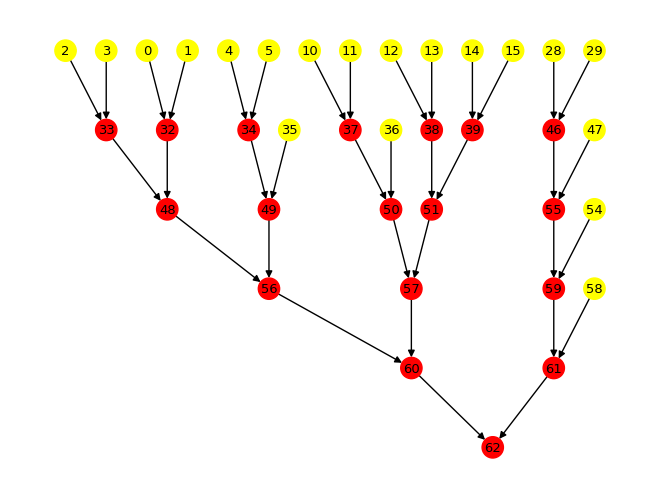

In [44]:
fig

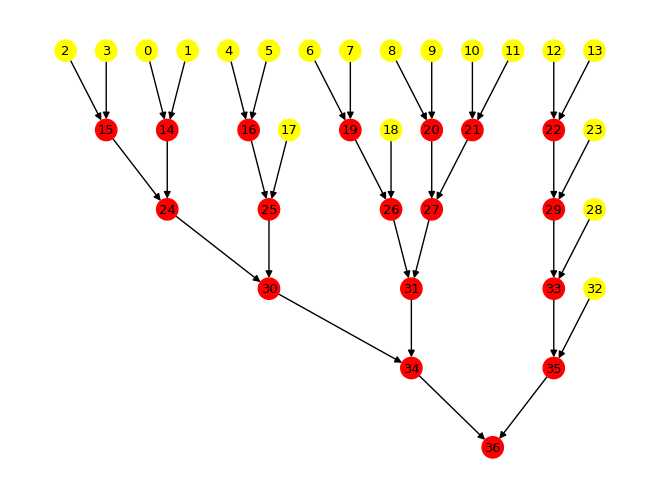

In [45]:
show_graph_with_labels(shrinked_adj, l, [label_names, leaf_ids], return_img = True)

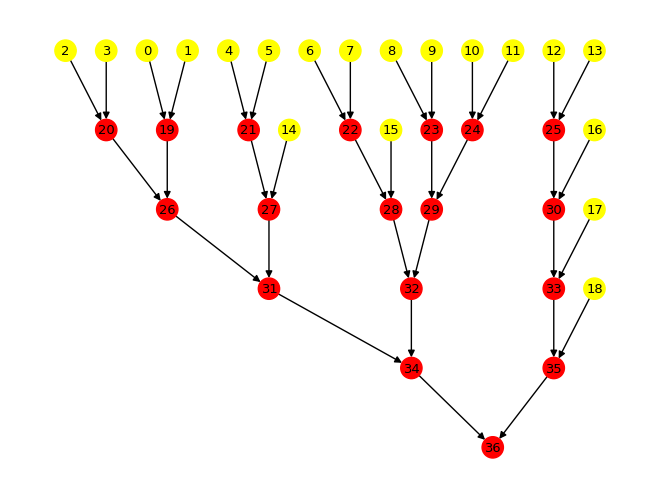

In [46]:
ordering = jnp.concatenate((leaf_ids, new_ance_ids))
reordered_adj = shrinked_adj[jnp.ix_(ordering, ordering)]

show_graph_with_labels(reordered_adj, l, return_img = True)

In [ ]:
new_leaves, new_all_seqs, adj = generate_general_groundtruth(metadata, perfect=False, seed = 45)

In [ ]:
from arg_parser_v2 import print_critical_info, print_bold_info

l = 9

netadata = {
    'n_all' : 2*l-1,
    'n_leaves' : l, 
    'n_ancestors' : l-1,
    'seq_length' : 4,
    'n_letters' : 4,
    'n_mutations' : 2,
}

x, _, tree = generate_general_groundtruth(netadata, perfect=True, seed = 45)

In [ ]:
x

In [ ]:
show_graph_with_labels(tree, l, return_img = True)  